In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import time
import copy
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# Hyperparameters
NUM_CLASSES = 3
BATCH_SIZE = 32

print(f'Nombre de classes: {NUM_CLASSES}')
print(f'Batch size: {BATCH_SIZE}')

Device: cuda
Nombre de classes: 3
Batch size: 32


In [2]:
# Transformations MNIST
transform_mnist = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Téléchargement MNIST
mnist_train_full = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_mnist)
mnist_test_full  = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_mnist)

def filter_mnist(dataset, classes=[0, 1, 8]):
    """Filtre MNIST pour ne garder que les classes spécifiées et réattribue les labels."""
    label_map = {0: 0, 1: 1, 8: 2}
    targets = dataset.targets
    mask = torch.zeros(len(targets), dtype=torch.bool)
    for c in classes:
        mask |= (targets == c)
    indices = mask.nonzero(as_tuple=True)[0].tolist()
    subset = Subset(dataset, indices)
    # Réattribution des labels
    new_targets = torch.tensor([label_map[targets[i].item()] for i in indices])
    return subset, new_targets, indices

train_subset, train_labels_mnist, train_idx_mnist = filter_mnist(mnist_train_full)
test_subset,  test_labels_mnist,  test_idx_mnist  = filter_mnist(mnist_test_full)

# Wrapper pour que le DataLoader ait les bons labels
class LabeledSubset(torch.utils.data.Dataset):
    def __init__(self, subset, labels):
        self.subset = subset
        self.labels = labels
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        x, _ = self.subset[idx]
        return x, self.labels[idx]

train_dataset_mnist = LabeledSubset(train_subset, train_labels_mnist)
test_dataset_mnist  = LabeledSubset(test_subset,  test_labels_mnist)

train_loader_mnist = DataLoader(train_dataset_mnist, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader_mnist  = DataLoader(test_dataset_mnist,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Train size: {len(train_dataset_mnist)}')
print(f'Test size:  {len(test_dataset_mnist)}')

# Vérification
imgs, lbls = next(iter(train_loader_mnist))
print(f'Batch shape: {imgs.shape}, Labels: {lbls[:8].tolist()}')

100%|██████████| 9.91M/9.91M [00:00<00:00, 55.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.72MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.5MB/s]


Train size: 18516
Test size:  3089
Batch shape: torch.Size([32, 1, 32, 32]), Labels: [1, 1, 2, 0, 2, 0, 0, 2]


In [3]:
def get_teacher_resnet50(num_classes=3):
    model = models.resnet50(pretrained=True)
    # Adapter l'entrée pour images 1 canal (MNIST)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    # Remplacer la dernière couche
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

teacher = get_teacher_resnet50(num_classes=NUM_CLASSES).to(device)
teacher.eval()  # Le teacher ne sera jamais entraîné

print('Teacher (ResNet-50) chargé et mis en mode évaluation.')
print(f'Paramètres du Teacher: {sum(p.numel() for p in teacher.parameters()):,}')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


Teacher (ResNet-50) chargé et mis en mode évaluation.
Paramètres du Teacher: 23,507,907


In [4]:
class MicroCNN(nn.Module):
    """Student léger pour MNIST — 3 couches conv + BN + ReLU + FC."""
    def __init__(self, num_classes=3):
        super(MicroCNN, self).__init__()
        self.features = nn.Sequential(
            # Conv1
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 16x16
            # Conv2
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 8x8
            # Conv3
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 4x4
        )
        self.classifier = nn.Linear(32 * 4 * 4, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

# Test d'instanciation
student_test = MicroCNN(num_classes=NUM_CLASSES).to(device)
total_params = sum(p.numel() for p in student_test.parameters())
print(f'MicroCNN — Paramètres: {total_params:,}')
assert total_params < 100_000, f'ERREUR: {total_params} >= 100000'
print('✓ Contrainte < 100 000 paramètres respectée')

MicroCNN — Paramètres: 7,539
✓ Contrainte < 100 000 paramètres respectée


In [5]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    print(f'Paramètres: {total:,} ({total/1e3:.1f}K)')
    return total

def model_size_kb(model):
    total_params = sum(p.numel() for p in model.parameters())
    size_bytes = total_params * 4  # float32 = 4 octets
    size_kb = size_bytes / 1024
    return size_kb

print('=== Teacher (ResNet-50) ===')
t_params = count_params(teacher)
t_size = model_size_kb(teacher)
print(f'Taille: {t_size/1024:.1f} Mo ({t_size:.1f} Ko)')

print('\n=== Student (MicroCNN) ===')
s_params = count_params(student_test)
s_size = model_size_kb(student_test)
print(f'Taille: {s_size:.1f} Ko')

ratio = t_params / s_params
print(f'\nRatio T/S (paramètres): {ratio:.1f}x')
print(f'Ratio T/S (taille): {t_size/s_size:.1f}x')

print('\n--- Tableau de synthèse ---')
print(f'| Modèle          | Paramètres     | Taille       |')
print(f'| Teacher ResNet  | {t_params/1e6:.2f}M          | {t_size/1024:.1f} Mo   |')
print(f'| Student MicroCNN| {s_params/1e3:.1f}K           | {s_size:.1f} Ko   |')
print(f'| Ratio T/S       | {ratio:.1f}x           | {t_size/s_size:.1f}x         |')

=== Teacher (ResNet-50) ===
Paramètres: 23,507,907 (23507.9K)
Taille: 89.7 Mo (91827.8 Ko)

=== Student (MicroCNN) ===
Paramètres: 7,539 (7.5K)
Taille: 29.4 Ko

Ratio T/S (paramètres): 3118.2x
Ratio T/S (taille): 3118.2x

--- Tableau de synthèse ---
| Modèle          | Paramètres     | Taille       |
| Teacher ResNet  | 23.51M          | 89.7 Mo   |
| Student MicroCNN| 7.5K           | 29.4 Ko   |
| Ratio T/S       | 3118.2x           | 3118.2x         |


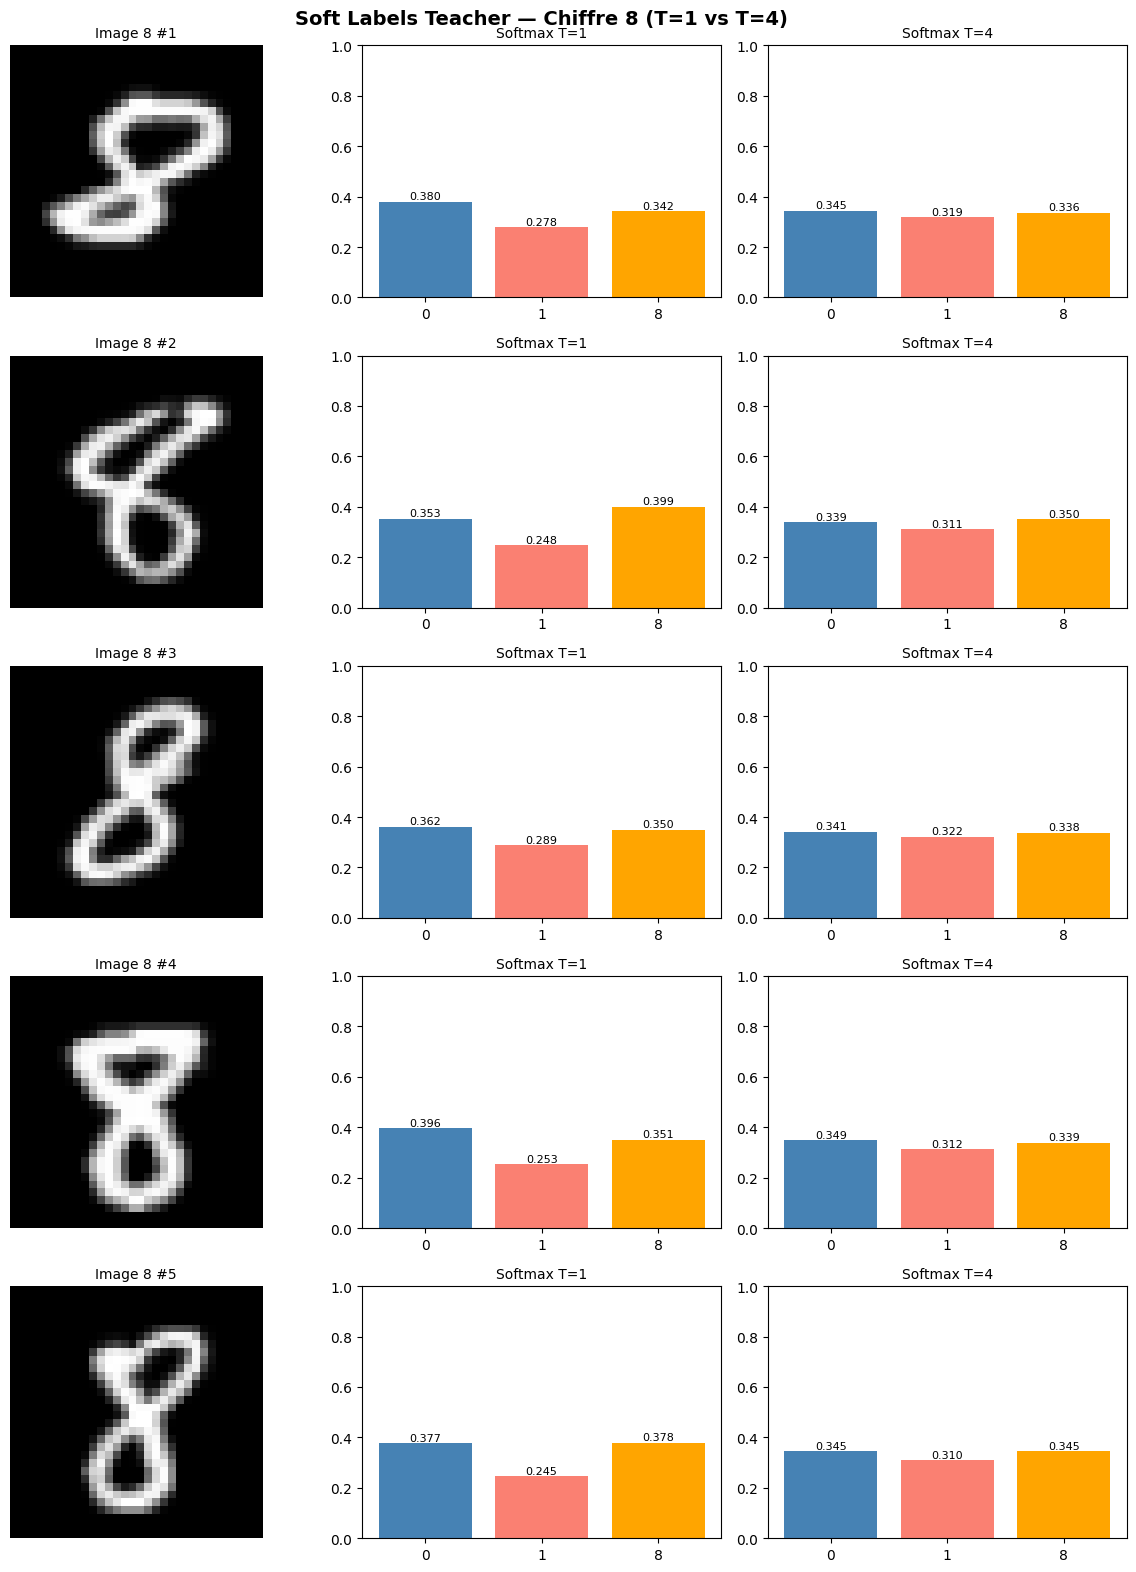

Figure sauvegardée: soft_labels_8.png


In [6]:
# Extraire 5 images du chiffre 8 (label réattribué = 2)
eights_indices = [i for i, (x, y) in enumerate(test_dataset_mnist) if y == 2][:5]

fig, axes = plt.subplots(5, 3, figsize=(12, 16))
class_names = ['0', '1', '8']

teacher.eval()
with torch.no_grad():
    for row, idx in enumerate(eights_indices):
        img, label = test_dataset_mnist[idx]
        img_t = img.unsqueeze(0).to(device)
        logits = teacher(img_t).cpu().squeeze()

        probs_T1 = F.softmax(logits / 1.0, dim=0).numpy()
        probs_T4 = F.softmax(logits / 4.0, dim=0).numpy()

        # Image
        axes[row, 0].imshow(img.squeeze().numpy(), cmap='gray')
        axes[row, 0].set_title(f'Image 8 #{row+1}', fontsize=10)
        axes[row, 0].axis('off')

        # Softmax T=1
        bars = axes[row, 1].bar(class_names, probs_T1, color=['steelblue', 'salmon', 'orange'])
        axes[row, 1].set_title(f'Softmax T=1', fontsize=10)
        axes[row, 1].set_ylim(0, 1)
        for bar, p in zip(bars, probs_T1):
            axes[row, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{p:.3f}', ha='center', fontsize=8)

        # Softmax T=4
        bars4 = axes[row, 2].bar(class_names, probs_T4, color=['steelblue', 'salmon', 'orange'])
        axes[row, 2].set_title(f'Softmax T=4', fontsize=10)
        axes[row, 2].set_ylim(0, 1)
        for bar, p in zip(bars4, probs_T4):
            axes[row, 2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{p:.3f}', ha='center', fontsize=8)

plt.suptitle('Soft Labels Teacher — Chiffre 8 (T=1 vs T=4)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('soft_labels_8.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée: soft_labels_8.png')

In [7]:
def kd_loss(student_logits, teacher_logits, true_labels, T, alpha):
    """
    Knowledge Distillation Loss:
    LKD = alpha * CE(y, yS) + (1-alpha) * T^2 * KL(softmax(zT/T) || softmax(zS/T))
    """
    # Distributions lissées
    soft_teacher = F.softmax(teacher_logits / T, dim=1)
    soft_student = F.log_softmax(student_logits / T, dim=1)

    # KL divergence * T^2
    kl_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (T ** 2)

    # Cross-entropy avec vraies étiquettes
    ce_loss = F.cross_entropy(student_logits, true_labels)

    # Combinaison
    loss = alpha * ce_loss + (1 - alpha) * kl_loss
    return loss

# Vérification numérique
zT = torch.tensor([[1.2, 0.5, 4.1]])
zS = torch.tensor([[0.9, 0.4, 3.6]])
y  = torch.tensor([2])
loss_val = kd_loss(zS, zT, y, T=4, alpha=0.4)
print(f'kd_loss calculée: {loss_val.item():.4f}')
print('(Valeur attendue selon calcul à la main: ~0.048 à 0.231 selon précision numérique)')

kd_loss calculée: 0.0488
(Valeur attendue selon calcul à la main: ~0.048 à 0.231 selon précision numérique)


In [8]:
def train_epoch(student, teacher, loader, optimizer, T, alpha):
    """Entraîne le student pour une epoch avec KD."""
    student.train()
    teacher.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)

        # Logits Teacher (sans gradient)
        with torch.no_grad():
            teacher_logits = teacher(imgs)

        # Logits Student
        student_logits = student(imgs)

        # Loss KD
        loss = kd_loss(student_logits, teacher_logits, labels, T, alpha)

        # Rétropropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        preds = student_logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader):
    """Calcule la précision du modèle sur loader."""
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
    return correct / total

print('Fonctions train_epoch et evaluate définies.')

Fonctions train_epoch et evaluate définies.


In [9]:
def run_experiment(T, alpha, label, epochs=30):
    """Instancie un Student, l'entraîne et retourne l'historique."""
    student = MicroCNN(num_classes=NUM_CLASSES).to(device)
    optimizer = optim.Adam(student.parameters(), lr=1e-3)

    history = {'train_loss': [], 'train_acc': [], 'val_acc': []}

    print(f'\n--- Expérience: {label} (T={T}, alpha={alpha}) ---')
    for epoch in range(1, epochs + 1):
        loss, tr_acc = train_epoch(student, teacher, train_loader_mnist, optimizer, T, alpha)
        val_acc = evaluate(student, test_loader_mnist)

        history['train_loss'].append(loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)

        if epoch % 5 == 0 or epoch == 1:
            print(f'  Epoch {epoch:3d}/{epochs} | Loss: {loss:.4f} | Train Acc: {tr_acc*100:.2f}% | Val Acc: {val_acc*100:.2f}%')

    print(f'  => Précision finale: {val_acc*100:.2f}%')
    return history, student

# Expérience 1a — Student seul (sans distillation)
hist_alone, model_alone = run_experiment(T=1, alpha=1.0, label='Student seul (sans KD)', epochs=30)

# Expérience 1b — Student distillé
hist_kd, model_kd = run_experiment(T=4, alpha=0.4, label='Student + KD classique (T=4)', epochs=30)


--- Expérience: Student seul (sans KD) (T=1, alpha=1.0) ---
  Epoch   1/30 | Loss: 0.0446 | Train Acc: 98.69% | Val Acc: 99.84%
  Epoch   5/30 | Loss: 0.0038 | Train Acc: 99.84% | Val Acc: 99.81%
  Epoch  10/30 | Loss: 0.0009 | Train Acc: 99.95% | Val Acc: 99.90%
  Epoch  15/30 | Loss: 0.0002 | Train Acc: 100.00% | Val Acc: 99.90%
  Epoch  20/30 | Loss: 0.0056 | Train Acc: 99.83% | Val Acc: 99.87%
  Epoch  25/30 | Loss: 0.0000 | Train Acc: 100.00% | Val Acc: 99.84%
  Epoch  30/30 | Loss: 0.0034 | Train Acc: 99.91% | Val Acc: 99.84%
  => Précision finale: 99.84%

--- Expérience: Student + KD classique (T=4) (T=4, alpha=0.4) ---
  Epoch   1/30 | Loss: 0.3027 | Train Acc: 98.90% | Val Acc: 99.55%
  Epoch   5/30 | Loss: 0.2942 | Train Acc: 99.87% | Val Acc: 99.74%
  Epoch  10/30 | Loss: 0.2933 | Train Acc: 99.92% | Val Acc: 99.84%
  Epoch  15/30 | Loss: 0.2928 | Train Acc: 99.96% | Val Acc: 99.84%
  Epoch  20/30 | Loss: 0.2924 | Train Acc: 99.97% | Val Acc: 99.87%
  Epoch  25/30 | Loss: 0

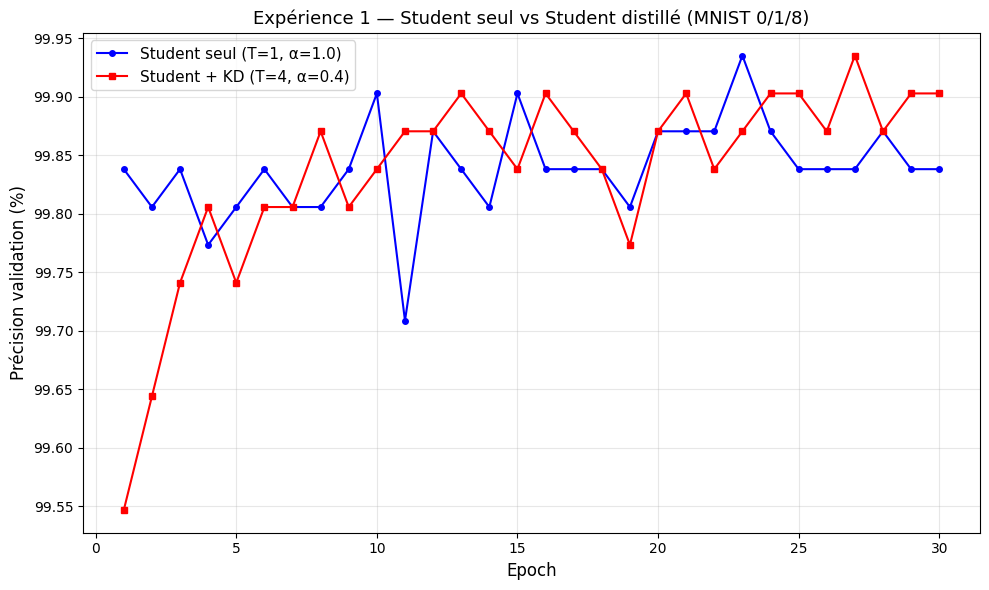

Précision finale Student seul : 99.84%
Précision finale Student + KD : 99.90%


In [10]:
# Courbes de précision
plt.figure(figsize=(10, 6))
epochs_range = range(1, 31)
plt.plot(epochs_range, [a*100 for a in hist_alone['val_acc']], 'b-o', markersize=4, label='Student seul (T=1, α=1.0)')
plt.plot(epochs_range, [a*100 for a in hist_kd['val_acc']],    'r-s', markersize=4, label='Student + KD (T=4, α=0.4)')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Précision validation (%)', fontsize=12)
plt.title('Expérience 1 — Student seul vs Student distillé (MNIST 0/1/8)', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('exp1_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Précision finale Student seul : {hist_alone["val_acc"][-1]*100:.2f}%')
print(f'Précision finale Student + KD : {hist_kd["val_acc"][-1]*100:.2f}%')


--- Expérience: T=1 (T=1, alpha=0.4) ---
  Epoch   1/15 | Loss: 0.3061 | Train Acc: 98.84% | Val Acc: 99.81%
  Epoch   5/15 | Loss: 0.2975 | Train Acc: 99.86% | Val Acc: 99.84%
  Epoch  10/15 | Loss: 0.2964 | Train Acc: 99.92% | Val Acc: 99.90%
  Epoch  15/15 | Loss: 0.2961 | Train Acc: 99.95% | Val Acc: 99.84%
  => Précision finale: 99.84%

--- Expérience: T=2 (T=2, alpha=0.4) ---
  Epoch   1/15 | Loss: 0.3074 | Train Acc: 98.31% | Val Acc: 99.71%
  Epoch   5/15 | Loss: 0.2962 | Train Acc: 99.81% | Val Acc: 99.90%
  Epoch  10/15 | Loss: 0.2948 | Train Acc: 99.92% | Val Acc: 99.90%
  Epoch  15/15 | Loss: 0.2944 | Train Acc: 99.92% | Val Acc: 99.90%
  => Précision finale: 99.90%

--- Expérience: T=4 (T=4, alpha=0.4) ---
  Epoch   1/15 | Loss: 0.3043 | Train Acc: 98.51% | Val Acc: 99.64%
  Epoch   5/15 | Loss: 0.2946 | Train Acc: 99.83% | Val Acc: 99.77%
  Epoch  10/15 | Loss: 0.2933 | Train Acc: 99.90% | Val Acc: 99.87%
  Epoch  15/15 | Loss: 0.2928 | Train Acc: 99.94% | Val Acc: 99.90

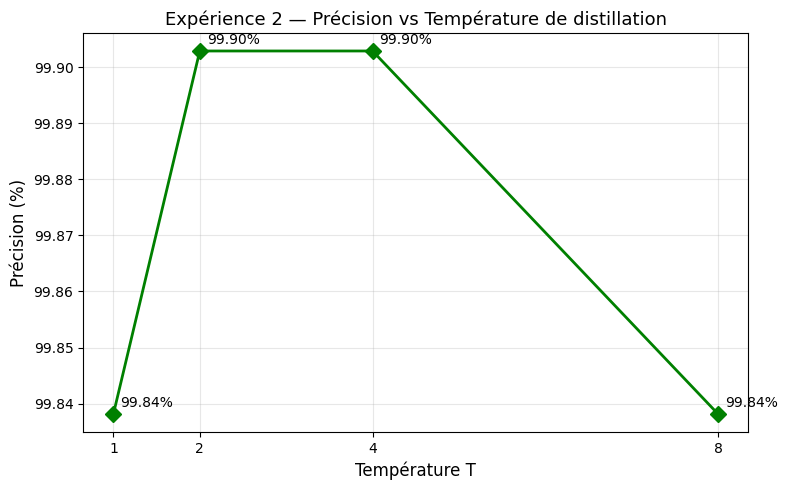

In [11]:
temperatures = [1, 2, 4, 8]
temp_results = {}

for T in temperatures:
    hist, _ = run_experiment(T=T, alpha=0.4, label=f'T={T}', epochs=15)
    temp_results[T] = hist['val_acc'][-1]

# Tableau et courbe
print('\n--- Résultats Expérience 2 ---')
print(f'{"T":>5} | {"Précision (%)":>15}')
print('-' * 25)
for T, acc in temp_results.items():
    print(f'{T:>5} | {acc*100:>15.2f}')

plt.figure(figsize=(8, 5))
plt.plot(list(temp_results.keys()), [v*100 for v in temp_results.values()], 'g-D', markersize=8, linewidth=2)
for T, acc in temp_results.items():
    plt.annotate(f'{acc*100:.2f}%', (T, acc*100), textcoords='offset points', xytext=(5, 5), fontsize=10)
plt.xlabel('Température T', fontsize=12)
plt.ylabel('Précision (%)', fontsize=12)
plt.title('Expérience 2 — Précision vs Température de distillation', fontsize=13)
plt.xticks(temperatures)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('exp2_temperature.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Student Grand — ResNet-18
def get_student_large(num_classes=3):
    model = models.resnet18(pretrained=False)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

# Student Petit — 2 conv, < 10 000 params
class TinyCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 4, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16x16
            nn.Conv2d(4, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 8x8
        )
        self.classifier = nn.Linear(8 * 8 * 8, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

tiny = TinyCNN()
print(f'Student Petit params: {sum(p.numel() for p in tiny.parameters()):,}')

def run_experiment_model(model_fn, T, alpha, epochs=15):
    model = model_fn().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        train_epoch(model, teacher, train_loader_mnist, optimizer, T, alpha)
    return evaluate(model, test_loader_mnist)

print('\nEntraînement Expérience 3...')
results_regime = {}

for name, fn in [('Grand (ResNet-18)', lambda: get_student_large()),
                 ('Moyen (MicroCNN)',   lambda: MicroCNN()),
                 ('Petit (TinyCNN)',    lambda: TinyCNN())]:
    acc_alone = run_experiment_model(fn, T=1, alpha=1.0, epochs=15)
    acc_kd    = run_experiment_model(fn, T=4, alpha=0.4, epochs=15)
    results_regime[name] = (acc_alone, acc_kd)
    print(f'  {name}: sans KD={acc_alone*100:.2f}% | avec KD={acc_kd*100:.2f}%')

print('\n--- Tableau Expérience 3 ---')
print(f'{"Student":<22} | {"Sans KD":>9} | {"Avec KD":>9} | Régime')
print('-' * 65)
for name, (acc_alone, acc_kd) in results_regime.items():
    diff = (acc_kd - acc_alone) * 100
    if diff > 0.5:
        regime = 'KD bénéfique'
    elif diff < -0.5:
        regime = 'KD pénalise (trop grand)'
    else:
        regime = 'KD neutre'
    print(f'{name:<22} | {acc_alone*100:>8.2f}% | {acc_kd*100:>8.2f}% | {regime}')

Student Petit params: 1,875

Entraînement Expérience 3...
  Grand (ResNet-18): sans KD=99.90% | avec KD=99.97%
  Moyen (MicroCNN): sans KD=99.94% | avec KD=99.90%
  Petit (TinyCNN): sans KD=99.71% | avec KD=99.71%

--- Tableau Expérience 3 ---
Student                |   Sans KD |   Avec KD | Régime
-----------------------------------------------------------------
Grand (ResNet-18)      |    99.90% |    99.97% | KD neutre
Moyen (MicroCNN)       |    99.94% |    99.90% | KD neutre
Petit (TinyCNN)        |    99.71% |    99.71% | KD neutre


In [13]:
def attention_map(feature_map):
    """
    Calcule la carte d'attention d'une feature map.
    A^(l) = (1/C) * sum_c |F^(l)_c|^2
    feature_map: (B, C, H, W)
    retourne: (B, H, W)
    """
    return feature_map.pow(2).mean(dim=1)  # moyenne sur les canaux

def at_loss(student_features, teacher_features, kd_loss_val, beta=0.1):
    """
    L_AT = L_KD + beta * sum_l ||A_T^(l)/||A_T^(l)||_2 - A_S^(l)/||A_S^(l)||_2||^2_2
    """
    at_term = 0.0
    for feat_s, feat_t in zip(student_features, teacher_features):
        # Redimensionner si nécessaire
        att_t = attention_map(feat_t.detach())
        att_s = attention_map(feat_s)

        # Resize student map vers teacher map si dimensions différentes
        if att_s.shape != att_t.shape:
            att_s = F.interpolate(att_s.unsqueeze(1), size=att_t.shape[-2:], mode='bilinear', align_corners=False).squeeze(1)

        # Normalisation L2
        att_t_norm = F.normalize(att_t.view(att_t.size(0), -1), dim=1)
        att_s_norm = F.normalize(att_s.view(att_s.size(0), -1), dim=1)

        at_term += (att_t_norm - att_s_norm).pow(2).sum(dim=1).mean()

    return kd_loss_val + beta * at_term

print('Fonctions attention_map et at_loss définies.')

Fonctions attention_map et at_loss définies.


In [14]:
def train_with_at(student, teacher, loader, optimizer, T, alpha, beta, epochs=30):
    """Entraîne avec KD + Attention Transfer via forward hooks."""
    history = {'val_acc': []}

    # Hooks pour extraire les feature maps
    teacher_feats = []
    student_feats = []

    def make_hook(store):
        def hook(module, input, output):
            store.append(output)
        return hook

    # Attacher hooks sur les dernières couches conv
    t_hooks = [teacher.layer3.register_forward_hook(make_hook(teacher_feats))]
    s_hooks = [student.features[8].register_forward_hook(make_hook(student_feats))]  # Conv3

    for epoch in range(1, epochs + 1):
        student.train()
        teacher.eval()
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            teacher_feats.clear()
            student_feats.clear()

            with torch.no_grad():
                teacher_logits = teacher(imgs)
            student_logits = student(imgs)

            base_loss = kd_loss(student_logits, teacher_logits, labels, T, alpha)
            loss = at_loss(student_feats, teacher_feats, base_loss, beta)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        val_acc = evaluate(student, test_loader_mnist)
        history['val_acc'].append(val_acc)
        if epoch % 5 == 0 or epoch == 1:
            print(f'  Epoch {epoch:3d}/{epochs} | Val Acc: {val_acc*100:.2f}%')

    # Retirer les hooks
    for h in t_hooks + s_hooks:
        h.remove()

    return history

print('Entraînement KD + AT...')
student_at = MicroCNN(num_classes=NUM_CLASSES).to(device)
optimizer_at = optim.Adam(student_at.parameters(), lr=1e-3)
hist_at = train_with_at(student_at, teacher, train_loader_mnist, optimizer_at,
                        T=4, alpha=0.4, beta=0.1, epochs=30)
print(f'Précision finale KD + AT: {hist_at["val_acc"][-1]*100:.2f}%')

Entraînement KD + AT...
  Epoch   1/30 | Val Acc: 99.77%
  Epoch   5/30 | Val Acc: 99.84%
  Epoch  10/30 | Val Acc: 99.77%
  Epoch  15/30 | Val Acc: 99.84%
  Epoch  20/30 | Val Acc: 99.87%
  Epoch  25/30 | Val Acc: 99.87%
  Epoch  30/30 | Val Acc: 99.84%
Précision finale KD + AT: 99.84%


In [15]:
def measure_latency(model, n=100, input_shape=(1, 1, 32, 32)):
    """Mesure la latence moyenne en ms sur n passages."""
    model.eval()
    dummy = torch.randn(*input_shape).to(device)

    # Chauffe (10 passes)
    with torch.no_grad():
        for _ in range(10):
            _ = model(dummy)

    # Mesure
    times = []
    with torch.no_grad():
        for _ in range(n):
            if device.type == 'cuda':
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            _ = model(dummy)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            times.append((time.perf_counter() - t0) * 1000)

    return np.mean(times)

lat_teacher  = measure_latency(teacher)
lat_alone    = measure_latency(model_alone)
lat_kd       = measure_latency(model_kd)
lat_at       = measure_latency(student_at)

acc_teacher  = evaluate(teacher, test_loader_mnist)
acc_alone    = hist_alone['val_acc'][-1]
acc_kd       = hist_kd['val_acc'][-1]
acc_at       = hist_at['val_acc'][-1]

size_student = model_size_kb(model_alone)

print('\n=== Tableau de Synthèse — Partie 1 ===')
print(f'{"Modèle":<25} | {"Taille":>12} | {"Latence":>10} | {"Précision":>10} | {"Puce IoT ?":>10}')
print('-' * 80)
print(f'{"Teacher (ResNet-50)":<25} | {"98 Mo":>12} | {lat_teacher:>8.2f} ms | {acc_teacher*100:>9.2f}% | {"NON":>10}')
print(f'{"Student seul":<25} | {f"{size_student:.1f} Ko":>12} | {lat_alone:>8.2f} ms | {acc_alone*100:>9.2f}% | {"OUI":>10}')
print(f'{"Student + KD":<25} | {f"{size_student:.1f} Ko":>12} | {lat_kd:>8.2f} ms | {acc_kd*100:>9.2f}% | {"OUI":>10}')
print(f'{"Student + KD + AT":<25} | {f"{size_student:.1f} Ko":>12} | {lat_at:>8.2f} ms | {acc_at*100:>9.2f}% | {"OUI":>10}')


=== Tableau de Synthèse — Partie 1 ===
Modèle                    |       Taille |    Latence |  Précision | Puce IoT ?
--------------------------------------------------------------------------------
Teacher (ResNet-50)       |        98 Mo |     5.25 ms |     33.96% |        NON
Student seul              |      29.4 Ko |     0.49 ms |     99.84% |        OUI
Student + KD              |      29.4 Ko |     0.49 ms |     99.90% |        OUI
Student + KD + AT         |      29.4 Ko |     0.49 ms |     99.84% |        OUI


---
# PARTIE 2 — (CIFAR-10)
## Classification d'animaux sur caméra embarquée

In [ ]:
NUM_CLASSES_P2 = 4
BATCH_SIZE_P2  = 64

# Classes CIFAR-10: chat=3, cerf=4, chien=5, cheval=7
CIFAR_CLASSES   = [3, 4, 5, 7]
CIFAR_LABEL_MAP = {3: 0, 4: 1, 5: 2, 7: 3}
CLASS_NAMES_P2  = ['chat', 'cerf', 'chien', 'cheval']

transform_train_cifar = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.4914, 0.4822, 0.4465], [0.2470, 0.2435, 0.2616])
])

transform_test_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.4914, 0.4822, 0.4465], [0.2470, 0.2435, 0.2616])
])

cifar_train_full = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=transform_train_cifar)
cifar_test_full  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test_cifar)

def filter_cifar(dataset, class_map):
    targets = torch.tensor(dataset.targets)
    classes = list(class_map.keys())
    mask = torch.zeros(len(targets), dtype=torch.bool)
    for c in classes:
        mask |= (targets == c)
    indices = mask.nonzero(as_tuple=True)[0].tolist()
    new_labels = torch.tensor([class_map[targets[i].item()] for i in indices])
    subset = Subset(dataset, indices)
    return LabeledSubset(subset, new_labels)

train_dataset_cifar = filter_cifar(cifar_train_full, CIFAR_LABEL_MAP)
test_dataset_cifar  = filter_cifar(cifar_test_full,  CIFAR_LABEL_MAP)

train_loader_cifar = DataLoader(train_dataset_cifar, batch_size=BATCH_SIZE_P2, shuffle=True,  num_workers=2)
test_loader_cifar  = DataLoader(test_dataset_cifar,  batch_size=BATCH_SIZE_P2, shuffle=False, num_workers=2)

print(f'Train CIFAR-10 filtré: {len(train_dataset_cifar)} images')
print(f'Test  CIFAR-10 filtré: {len(test_dataset_cifar)} images')

100%|██████████| 170M/170M [00:02<00:00, 74.4MB/s]


Train CIFAR-10 filtré: 20000 images
Test  CIFAR-10 filtré: 4000 images


In [ ]:
# Teacher VGG-16
teacher_vgg = models.vgg16(pretrained=True)
teacher_vgg.classifier[-1] = nn.Linear(4096, NUM_CLASSES_P2)
teacher_vgg = teacher_vgg.to(device)
teacher_vgg.eval()

print('=== Teacher (VGG-16) ===')
t2_params = count_params(teacher_vgg)
t2_size   = model_size_kb(teacher_vgg)
print(f'Taille: {t2_size/1024:.1f} Mo')

# Student TinyCNN — 4 couches conv
class TinyCNN_CIFAR(nn.Module):
    """Student pour CIFAR-10: 4 couches conv (16->32->64->128), < 200K params."""
    def __init__(self, num_classes=4):
        super(TinyCNN_CIFAR, self).__init__()
        self.features = nn.Sequential(
            # Conv1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            # Conv2 + MaxPool
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 16x16
            # Conv3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            # Conv4 + MaxPool
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 8x8
        )
        self.classifier = nn.Linear(128 * 8 * 8, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

print('\n=== Student (TinyCNN CIFAR) ===')
s2_test   = TinyCNN_CIFAR(num_classes=NUM_CLASSES_P2).to(device)
s2_params = count_params(s2_test)
s2_size   = model_size_kb(s2_test)
print(f'Taille: {s2_size/1024:.2f} Mo')
assert s2_params < 200_000
print('✓ Contrainte < 200 000 paramètres respectée')

print(f'\nRatio T/S: {t2_params/s2_params:.1f}x')

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 230MB/s]


=== Teacher (VGG-16) ===
Paramètres: 134,276,932 (134276.9K)
Taille: 512.2 Mo

=== Student (TinyCNN CIFAR) ===
Paramètres: 130,692 (130.7K)
Taille: 0.50 Mo
✓ Contrainte < 200 000 paramètres respectée

Ratio T/S: 1027.4x


In [ ]:
def train_epoch_cifar(student, teacher, loader, optimizer, T, alpha):
    student.train()
    teacher.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.no_grad():
            teacher_logits = teacher(imgs)
        student_logits = student(imgs)
        loss = kd_loss(student_logits, teacher_logits, labels, T, alpha)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        preds = student_logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def run_cifar_experiment(T, alpha, label, epochs=30):
    student = TinyCNN_CIFAR(num_classes=NUM_CLASSES_P2).to(device)
    optimizer = optim.Adam(student.parameters(), lr=1e-3)
    history = {'val_acc': []}
    print(f'\n--- {label} ---')
    for epoch in range(1, epochs + 1):
        loss, tr_acc = train_epoch_cifar(student, teacher_vgg, train_loader_cifar, optimizer, T, alpha)
        val_acc = evaluate(student, test_loader_cifar)
        history['val_acc'].append(val_acc)
        if epoch % 10 == 0 or epoch == 1:
            print(f'  Epoch {epoch:3d}/{epochs} | Loss: {loss:.4f} | Val Acc: {val_acc*100:.2f}%')
    print(f'  => Précision finale: {history["val_acc"][-1]*100:.2f}%')
    return history, student

hist_cifar_alone, model_cifar_alone = run_cifar_experiment(T=1, alpha=1.0, label='Student seul CIFAR', epochs=30)
hist_cifar_kd,    model_cifar_kd    = run_cifar_experiment(T=4, alpha=0.4, label='Student + KD CIFAR (T=4)', epochs=30)


--- Student seul CIFAR ---
  Epoch   1/30 | Loss: 1.1147 | Val Acc: 64.68%
  Epoch  10/30 | Loss: 0.3848 | Val Acc: 79.35%
  Epoch  20/30 | Loss: 0.1530 | Val Acc: 80.67%
  Epoch  30/30 | Loss: 0.0698 | Val Acc: 81.77%
  => Précision finale: 81.77%

--- Student + KD CIFAR (T=4) ---
  Epoch   1/30 | Loss: 0.6827 | Val Acc: 41.23%
  Epoch  10/30 | Loss: 0.4883 | Val Acc: 71.45%
  Epoch  20/30 | Loss: 0.4462 | Val Acc: 78.70%
  Epoch  30/30 | Loss: 0.4186 | Val Acc: 76.53%
  => Précision finale: 76.53%


In [ ]:
# ── Inspection des shapes réels avant de définir l'adapter ───────────────────
def get_shape_at_layer(model, layer, loader):
    store = []
    h = layer.register_forward_hook(lambda m, i, o: store.append(o))
    imgs, _ = next(iter(loader))
    with torch.no_grad():
        model(imgs.to(device))
    h.remove()
    return store[0].shape if store else None

# VGG-16 : on cherche un layer avec ~256 canaux et taille spatiale raisonnable
print('=== Shapes VGG-16 features ===')
for idx in [4, 9, 16, 23]:
    sh = get_shape_at_layer(teacher_vgg, teacher_vgg.features[idx], train_loader_cifar)
    print(f'  features[{idx:2d}] : {sh}')

print('\n=== Shapes TinyCNN features ===')
tmp_student = TinyCNN_CIFAR(num_classes=NUM_CLASSES_P2).to(device)
for idx in [2, 5, 9, 12]:
    sh = get_shape_at_layer(tmp_student, tmp_student.features[idx], train_loader_cifar)
    print(f'  features[{idx:2d}] : {sh}')

=== Shapes VGG-16 features ===
  features[ 4] : torch.Size([64, 64, 16, 16])
  features[ 9] : torch.Size([64, 128, 8, 8])
  features[16] : torch.Size([64, 256, 4, 4])
  features[23] : torch.Size([64, 512, 2, 2])

=== Shapes TinyCNN features ===
  features[ 2] : torch.Size([64, 16, 32, 32])
  features[ 5] : torch.Size([64, 32, 32, 32])
  features[ 9] : torch.Size([64, 64, 16, 16])
  features[12] : torch.Size([64, 128, 16, 16])


In [ ]:
# ── TÂCHE 21 — Couche d'adaptation FitNets ───────────────────────────────────

def fitnets_loss(student_feat, teacher_feat, adapter, gamma, kd_loss_val):
    """L_FitNets = L_KD + gamma * ||phi(F_S) - F_T||^2"""
    adapted = adapter(student_feat)
    if adapted.shape[-2:] != teacher_feat.shape[-2:]:
        adapted = F.interpolate(adapted, size=teacher_feat.shape[-2:],
                                mode='bilinear', align_corners=False)
    feat_loss = F.mse_loss(adapted, teacher_feat.detach())
    return kd_loss_val + gamma * feat_loss

print('fitnets_loss définie.')

fitnets_loss définie.


In [ ]:
# ── TÂCHE 22 — Entraînement FitNets (Teacher sur CPU pour économiser VRAM) ───
import gc

def train_fitnets_lowmem(gamma, T=4, alpha=0.4, epochs=30):
    student = TinyCNN_CIFAR(num_classes=NUM_CLASSES_P2).to(device)

    # Teacher sur CPU pour libérer les ~14 Go de VRAM
    teacher_vgg.cpu()
    torch.cuda.empty_cache()

    # Passe test pour connaître les dimensions
    imgs_test, _ = next(iter(train_loader_cifar))
    _tf, _sf = [], []
    _th = teacher_vgg.features[9].register_forward_hook(lambda m,i,o: _tf.append(o))
    _sh = student.features[9].register_forward_hook(lambda m,i,o: _sf.append(o))
    with torch.no_grad():
        teacher_vgg(imgs_test.cpu())
        student(imgs_test.to(device))
    _th.remove(); _sh.remove()
    t_ch = _tf[0].shape[1]
    s_ch = _sf[0].shape[1]
    del _tf, _sf, imgs_test
    torch.cuda.empty_cache()

    print(f'  FitNets gamma={gamma} | Student ch={s_ch} → Teacher ch={t_ch}')

    adapter   = nn.Conv2d(s_ch, t_ch, kernel_size=1).to(device)
    optimizer = optim.Adam(
        list(student.parameters()) + list(adapter.parameters()), lr=1e-3)

    history = {'val_acc': []}

    for epoch in range(1, epochs + 1):
        student.train(); adapter.train(); teacher_vgg.eval()

        for imgs, labels in train_loader_cifar:
            labels = labels.to(device)

            # Teacher forward sur CPU
            t_feat_store = []
            t_hook = teacher_vgg.features[9].register_forward_hook(
                lambda m,i,o: t_feat_store.append(o.detach()))
            with torch.no_grad():
                t_logits_cpu = teacher_vgg(imgs.cpu())
            t_hook.remove()

            t_logits   = t_logits_cpu.to(device)
            t_feat_gpu = t_feat_store[0].to(device)
            del t_feat_store, t_logits_cpu

            # Student forward sur GPU
            s_feat_store = []
            s_hook = student.features[9].register_forward_hook(
                lambda m,i,o: s_feat_store.append(o))
            s_logits = student(imgs.to(device))
            s_hook.remove()

            base = kd_loss(s_logits, t_logits, labels, T, alpha)
            loss = fitnets_loss(s_feat_store[0], t_feat_gpu, adapter, gamma, base)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            del s_feat_store, t_feat_gpu, t_logits, s_logits, base, loss

        val_acc = evaluate(student, test_loader_cifar)
        history['val_acc'].append(val_acc)
        if epoch % 10 == 0:
            print(f'    Epoch {epoch}/{epochs} | Val: {val_acc*100:.2f}%')

    # Remettre le teacher sur GPU pour les cellules suivantes
    teacher_vgg.to(device)
    torch.cuda.empty_cache()
    print(f'  => Précision finale: {history["val_acc"][-1]*100:.2f}%')
    return history, student


# Lancement — un gamma à la fois
fitnets_results = {}
fitnets_models  = {}

for gamma in [0.1, 0.5, 1.0]:
    gc.collect()
    torch.cuda.empty_cache()
    h, m = train_fitnets_lowmem(gamma=gamma, epochs=30)
    fitnets_results[gamma] = h['val_acc'][-1]
    fitnets_models[gamma]  = m
    del h
    gc.collect()
    torch.cuda.empty_cache()

print('\n--- Tableau FitNets ---')
for g, acc in sorted(fitnets_results.items()):
    print(f'  gamma={g:.1f} | {acc*100:.2f}%')

  FitNets gamma=0.1 | Student ch=64 → Teacher ch=128
    Epoch 10/30 | Val: 75.70%
    Epoch 20/30 | Val: 73.83%
    Epoch 30/30 | Val: 75.33%
  => Précision finale: 75.33%
  FitNets gamma=0.5 | Student ch=64 → Teacher ch=128
    Epoch 10/30 | Val: 67.75%
    Epoch 20/30 | Val: 78.12%
    Epoch 30/30 | Val: 68.55%
  => Précision finale: 68.55%
  FitNets gamma=1.0 | Student ch=64 → Teacher ch=128
    Epoch 10/30 | Val: 76.33%
    Epoch 20/30 | Val: 71.97%
    Epoch 30/30 | Val: 75.72%
  => Précision finale: 75.72%

--- Tableau FitNets ---
  gamma=0.1 | 75.33%
  gamma=0.5 | 68.55%
  gamma=1.0 | 75.72%


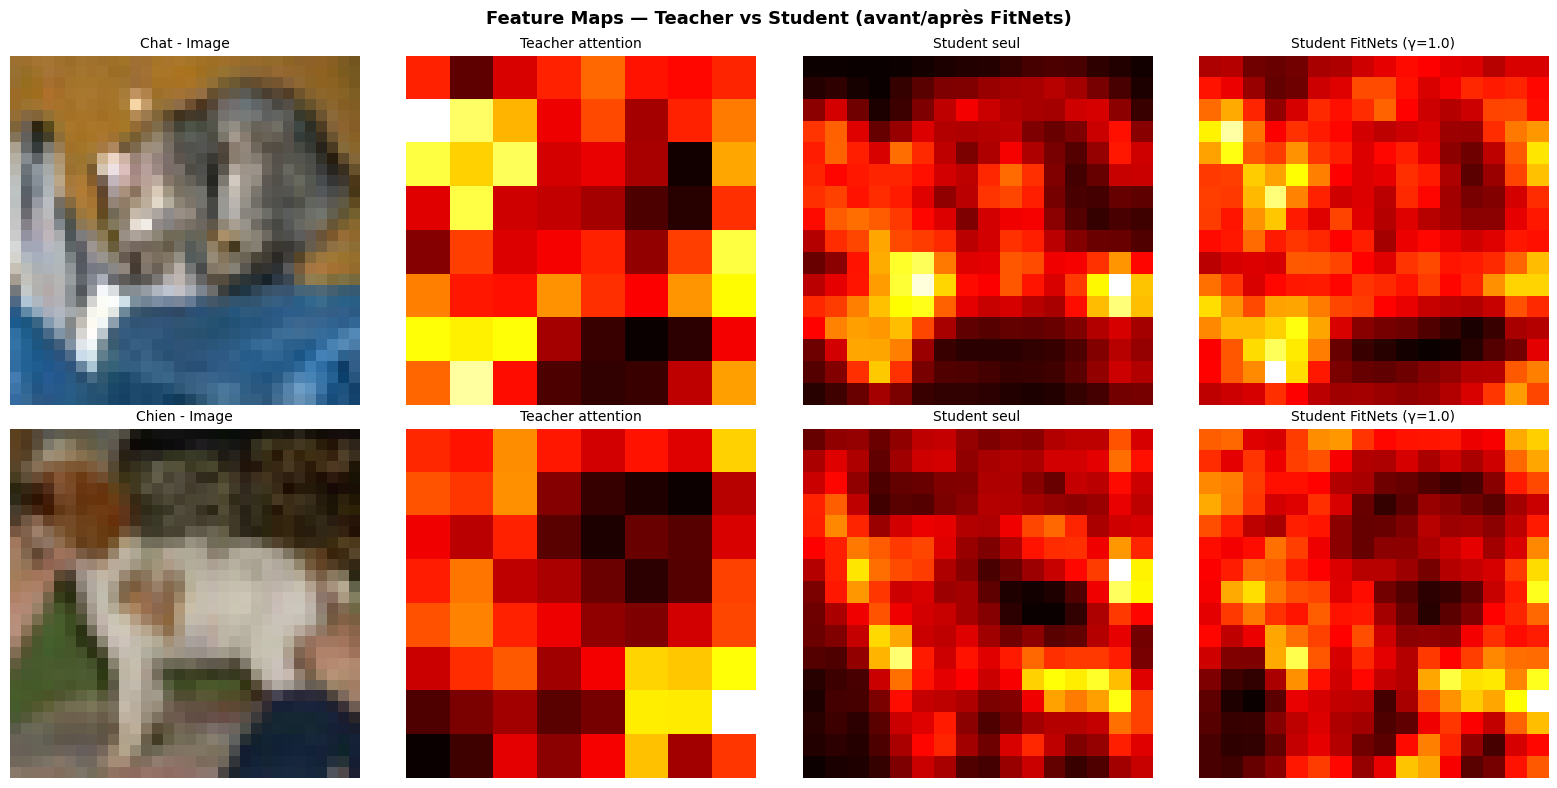

Sauvegardé: fitnets_featuremaps.png


In [ ]:
def get_feature_map(model, layer, img_tensor):
    feat = []
    h = layer.register_forward_hook(lambda m, i, o: feat.append(o))
    model.eval()
    with torch.no_grad():
        model(img_tensor.unsqueeze(0).to(device))
    h.remove()
    return feat[0].squeeze(0).cpu()

# Prendre une image de chat (label=0) et une image de chien (label=2)
def get_sample(dataset, label, n=1):
    imgs = []
    for x, y in dataset:
        if y == label:
            imgs.append(x)
            if len(imgs) == n: break
    return imgs[0]

img_chat  = get_sample(test_dataset_cifar, label=0)
img_chien = get_sample(test_dataset_cifar, label=2)

best_gamma = max(fitnets_results, key=fitnets_results.get)
student_fitnets = fitnets_models[best_gamma]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
animals = [('Chat', img_chat), ('Chien', img_chien)]

for row, (animal_name, img) in enumerate(animals):
    # Image originale (dé-normaliser)
    img_vis = img.permute(1, 2, 0).numpy()
    img_vis = (img_vis * np.array([0.2470, 0.2435, 0.2616]) + np.array([0.4914, 0.4822, 0.4465])).clip(0, 1)
    axes[row, 0].imshow(img_vis)
    axes[row, 0].set_title(f'{animal_name} - Image', fontsize=10)
    axes[row, 0].axis('off')

    # Feature Teacher (VGG layer 9)
    feat_t = get_feature_map(teacher_vgg, teacher_vgg.features[9], img)
    att_t  = feat_t.pow(2).mean(0).numpy()
    axes[row, 1].imshow(att_t, cmap='hot')
    axes[row, 1].set_title('Teacher attention', fontsize=10)
    axes[row, 1].axis('off')

    # Feature Student sans KD (avant FitNets)
    feat_s0 = get_feature_map(model_cifar_alone, model_cifar_alone.features[7], img)
    att_s0  = feat_s0.pow(2).mean(0).numpy()
    axes[row, 2].imshow(att_s0, cmap='hot')
    axes[row, 2].set_title('Student seul', fontsize=10)
    axes[row, 2].axis('off')

    # Feature Student après FitNets
    feat_sf = get_feature_map(student_fitnets, student_fitnets.features[7], img)
    att_sf  = feat_sf.pow(2).mean(0).numpy()
    axes[row, 3].imshow(att_sf, cmap='hot')
    axes[row, 3].set_title(f'Student FitNets (γ={best_gamma})', fontsize=10)
    axes[row, 3].axis('off')

plt.suptitle('Feature Maps — Teacher vs Student (avant/après FitNets)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fitnets_featuremaps.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé: fitnets_featuremaps.png')

In [ ]:
def rkd_distance_loss(feat_T, feat_S):
    """
    RKD-D: pour chaque paire (i,j), normaliser par mu et appliquer Huber loss.
    """
    # Aplatir
    fT = feat_T.view(feat_T.size(0), -1)
    fS = feat_S.view(feat_S.size(0), -1)

    # Distances euclidiennes pairwise Teacher
    dT = torch.cdist(fT, fT)  # (N, N)
    dS = torch.cdist(fS, fS)

    # Normalisation par la distance moyenne
    mu_T = dT.mean() + 1e-8
    mu_S = dS.mean() + 1e-8
    dT_norm = dT / mu_T
    dS_norm = dS / mu_S

    # Huber loss
    loss = F.huber_loss(dS_norm, dT_norm.detach())
    return loss

def rkd_angle_loss(feat_T, feat_S, n_triplets=64):
    """
    RKD-A: cosinus de l'angle pour des triplets (i,j,k).
    """
    fT = feat_T.view(feat_T.size(0), -1)
    fS = feat_S.view(feat_S.size(0), -1)
    N  = fT.size(0)

    if N < 3:
        return torch.tensor(0.0, device=feat_T.device)

    # Sous-ensemble aléatoire de triplets
    idx = torch.randint(0, N, (n_triplets, 3), device=feat_T.device)
    i, j, k = idx[:, 0], idx[:, 1], idx[:, 2]

    # Vecteurs
    vT_ij = fT[i] - fT[j]
    vT_kj = fT[k] - fT[j]
    vS_ij = fS[i] - fS[j]
    vS_kj = fS[k] - fS[j]

    # Cosinus
    cos_T = F.cosine_similarity(vT_ij, vT_kj, dim=1)
    cos_S = F.cosine_similarity(vS_ij, vS_kj, dim=1)

    return F.huber_loss(cos_S, cos_T.detach())

print('RKD-D et RKD-A définis.')

RKD-D et RKD-A définis.


In [ ]:
def train_rkd(lambda_d, lambda_a, T=4, alpha=0.4, epochs=30, label='RKD'):
    student = TinyCNN_CIFAR(num_classes=NUM_CLASSES_P2).to(device)
    optimizer = optim.Adam(student.parameters(), lr=1e-3)

    teacher_feats = []
    student_feats = []

    def make_hook(store):
        def h(m, inp, out): store.append(out)
        return h

    # Hooks sur les avant-dernières couches pour extraire représentations
    t_hook = teacher_vgg.features[28].register_forward_hook(make_hook(teacher_feats))
    s_hook = student.features[12].register_forward_hook(make_hook(student_feats))

    history = {'val_acc': []}
    print(f'  {label} (λD={lambda_d}, λA={lambda_a})')

    for epoch in range(1, epochs + 1):
        student.train()
        teacher_vgg.eval()
        for imgs, labels in train_loader_cifar:
            imgs, labels = imgs.to(device), labels.to(device)
            teacher_feats.clear()
            student_feats.clear()

            with torch.no_grad():
                t_logits = teacher_vgg(imgs)
            s_logits = student(imgs)

            base = kd_loss(s_logits, t_logits, labels, T, alpha)

            rkd_d = rkd_distance_loss(teacher_feats[0], student_feats[0]) if lambda_d > 0 else 0
            rkd_a = rkd_angle_loss(teacher_feats[0], student_feats[0])    if lambda_a > 0 else 0
            loss  = base + lambda_d * rkd_d + lambda_a * rkd_a

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        val_acc = evaluate(student, test_loader_cifar)
        history['val_acc'].append(val_acc)
        if epoch % 10 == 0:
            print(f'    Epoch {epoch}/{epochs} | Val: {val_acc*100:.2f}%')

    t_hook.remove()
    s_hook.remove()
    print(f'    => Précision finale: {history["val_acc"][-1]*100:.2f}%')
    return history, student

rkd_configs = [
    (1.0, 0.0, 'RKD-D uniquement'),
    (0.0, 2.0, 'RKD-A uniquement'),
    (1.0, 2.0, 'RKD combiné'),
]

rkd_results = {}
rkd_models  = {}
for lD, lA, label in rkd_configs:
    h, m = train_rkd(lD, lA, label=label, epochs=30)
    rkd_results[label] = h['val_acc'][-1]
    rkd_models[label]  = m

print('\n--- Résultats RKD ---')
for k, v in rkd_results.items():
    print(f'  {k}: {v*100:.2f}%')

  RKD-D uniquement (λD=1.0, λA=0.0)
    Epoch 10/30 | Val: 73.25%
    Epoch 20/30 | Val: 78.10%
    Epoch 30/30 | Val: 75.05%
    => Précision finale: 75.05%
  RKD-A uniquement (λD=0.0, λA=2.0)
    Epoch 10/30 | Val: 72.45%
    Epoch 20/30 | Val: 75.55%
    Epoch 30/30 | Val: 75.20%
    => Précision finale: 75.20%
  RKD combiné (λD=1.0, λA=2.0)
    Epoch 10/30 | Val: 75.12%
    Epoch 20/30 | Val: 76.60%
    Epoch 30/30 | Val: 76.85%
    => Précision finale: 76.85%

--- Résultats RKD ---
  RKD-D uniquement: 75.05%
  RKD-A uniquement: 75.20%
  RKD combiné: 76.85%


Extraction des représentations...
t-SNE...


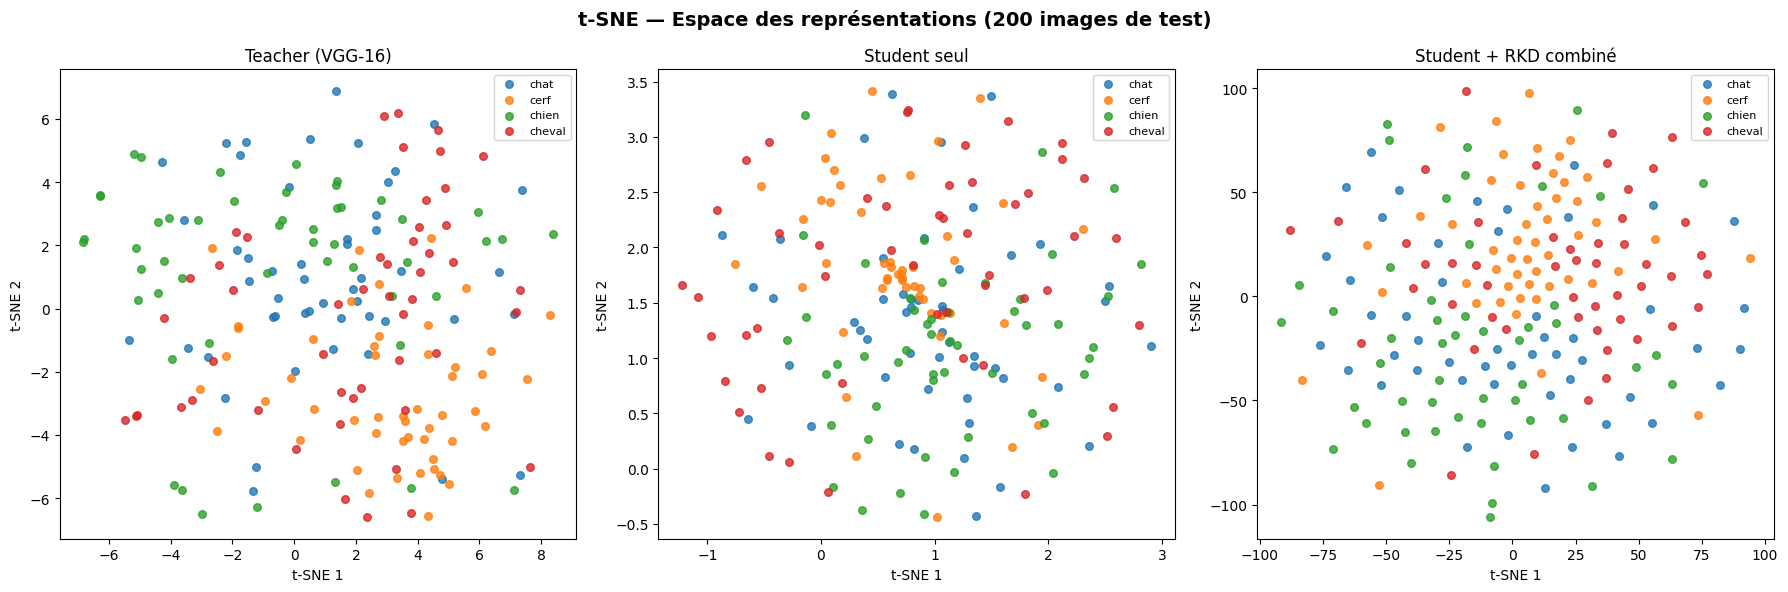

Sauvegardé: tsne_rkd.png


In [ ]:
def extract_representations(model, dataset, n_per_class=50, hook_layer=None):
    """Extrait les représentations de n_per_class images par classe."""
    model.eval()
    all_feats  = []
    all_labels = []
    count = {0: 0, 1: 0, 2: 0, 3: 0}

    feat_store = []
    if hook_layer is not None:
        hook = hook_layer.register_forward_hook(lambda m, i, o: feat_store.append(o))

    with torch.no_grad():
        for img, label in dataset:
            lbl = label.item() if torch.is_tensor(label) else label
            if count[lbl] >= n_per_class:
                continue
            feat_store.clear()
            out = model(img.unsqueeze(0).to(device))
            if hook_layer is not None and feat_store:
                rep = feat_store[0].squeeze(0).view(-1).cpu().numpy()
            else:
                rep = out.squeeze(0).cpu().numpy()
            all_feats.append(rep)
            all_labels.append(lbl)
            count[lbl] += 1
            if all(v >= n_per_class for v in count.values()):
                break

    if hook_layer is not None:
        hook.remove()

    return np.array(all_feats), np.array(all_labels)

print('Extraction des représentations...')
feats_teacher, labels_200 = extract_representations(teacher_vgg, test_dataset_cifar,
                                                     hook_layer=teacher_vgg.features[28])
feats_alone,   _          = extract_representations(model_cifar_alone, test_dataset_cifar,
                                                     hook_layer=model_cifar_alone.features[12])
feats_rkd,     _          = extract_representations(rkd_models['RKD combiné'], test_dataset_cifar,
                                                     hook_layer=rkd_models['RKD combiné'].features[12])

print('t-SNE...')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for ax, (feats, title) in zip(axes, [
    (feats_teacher, 'Teacher (VGG-16)'),
    (feats_alone,   'Student seul'),
    (feats_rkd,     'Student + RKD combiné')
]):
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    proj = tsne.fit_transform(feats)
    for cls in range(4):
        mask = labels_200 == cls
        ax.scatter(proj[mask, 0], proj[mask, 1], c=colors[cls], label=CLASS_NAMES_P2[cls], s=30, alpha=0.8)
    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=8)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

plt.suptitle('t-SNE — Espace des représentations (200 images de test)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('tsne_rkd.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé: tsne_rkd.png')

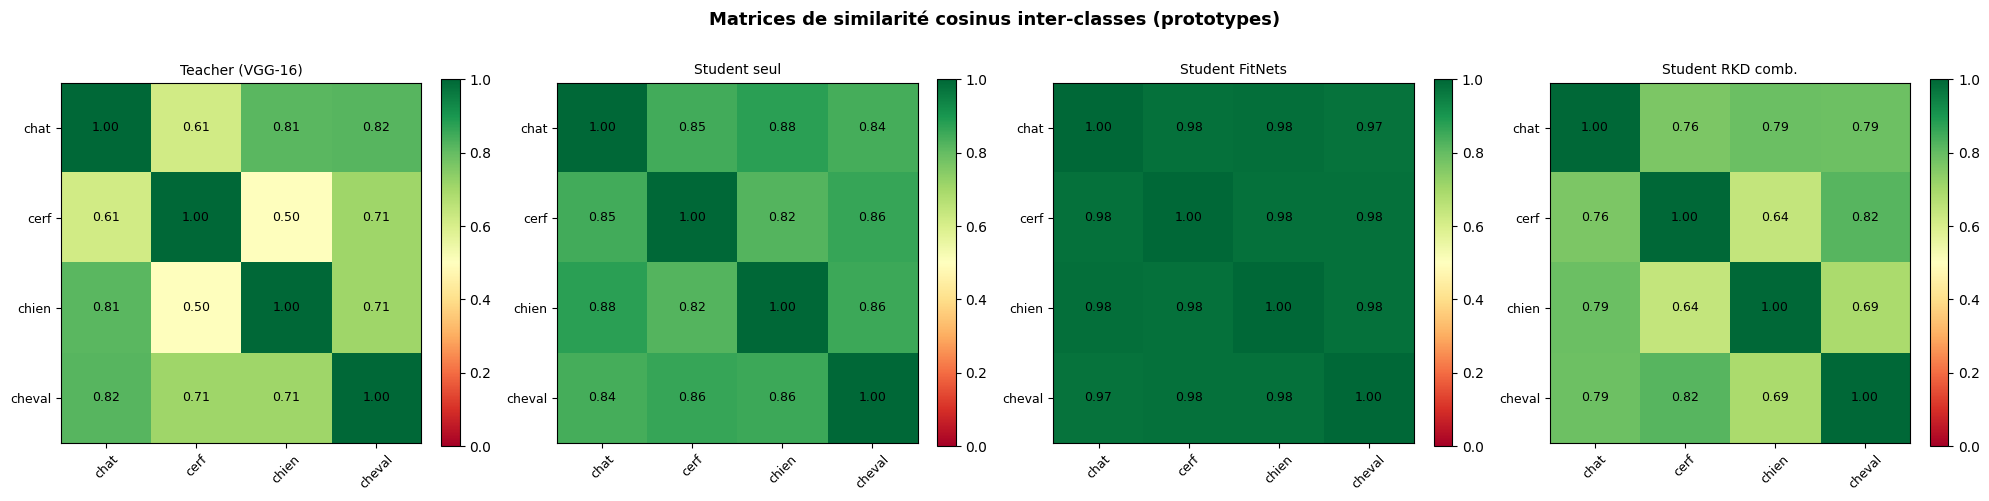

Sauvegardé: similarity_matrices.png


In [ ]:
def compute_class_prototypes(feats, labels, n_classes=4):
    """Calcule le prototype (moyenne) de chaque classe."""
    prototypes = []
    for c in range(n_classes):
        mask = labels == c
        prototypes.append(feats[mask].mean(axis=0))
    return np.array(prototypes)

def cosine_similarity_matrix(prototypes):
    """Matrice de similarité cosinus 4x4."""
    norms = np.linalg.norm(prototypes, axis=1, keepdims=True) + 1e-8
    normed = prototypes / norms
    return normed @ normed.T

# FitNets features
feats_fitnets, _ = extract_representations(student_fitnets, test_dataset_cifar,
                                            hook_layer=student_fitnets.features[7])

all_models_feats = [
    ('Teacher (VGG-16)', feats_teacher),
    ('Student seul',     feats_alone),
    ('Student FitNets',  feats_fitnets),
    ('Student RKD comb.', feats_rkd),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, feats) in zip(axes, all_models_feats):
    protos = compute_class_prototypes(feats, labels_200)
    sim_mat = cosine_similarity_matrix(protos)
    im = ax.imshow(sim_mat, cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticklabels(CLASS_NAMES_P2, rotation=45, fontsize=9)
    ax.set_yticklabels(CLASS_NAMES_P2, fontsize=9)
    ax.set_title(title, fontsize=10)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{sim_mat[i,j]:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if sim_mat[i,j] < 0.5 else 'black')
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle('Matrices de similarité cosinus inter-classes (prototypes)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('similarity_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé: similarity_matrices.png')

In [ ]:
lat_teacher_vgg  = measure_latency(teacher_vgg,  input_shape=(1, 3, 32, 32))
lat_cifar_alone  = measure_latency(model_cifar_alone, input_shape=(1, 3, 32, 32))
lat_cifar_kd     = measure_latency(model_cifar_kd,    input_shape=(1, 3, 32, 32))
lat_fitnets_best = measure_latency(student_fitnets,   input_shape=(1, 3, 32, 32))
lat_rkd_comb     = measure_latency(rkd_models['RKD combiné'], input_shape=(1, 3, 32, 32))

acc_teacher_vgg  = evaluate(teacher_vgg, test_loader_cifar)
acc_cifar_alone  = hist_cifar_alone['val_acc'][-1]
acc_cifar_kd     = hist_cifar_kd['val_acc'][-1]
acc_fitnets_best = fitnets_results[best_gamma]
acc_rkd_comb     = rkd_results['RKD combiné']

s2_size_mo = model_size_kb(model_cifar_alone) / 1024

print('\n=== Tableau de Synthèse — Partie 2 ===')
print(f'{"Modèle":<28} | {"Taille":>10} | {"Latence":>10} | {"Précision":>10} | {"Caméra OK?"}' )
print('-' * 85)
rows = [
    ('Teacher (VGG-16)',      '130 Mo',              lat_teacher_vgg,  acc_teacher_vgg,  'NON'),
    ('Student seul',          f'{s2_size_mo:.2f} Mo', lat_cifar_alone,  acc_cifar_alone,  'OUI'),
    ('Student + KD (réf.)',   f'{s2_size_mo:.2f} Mo', lat_cifar_kd,     acc_cifar_kd,     'OUI'),
    ('Student + FitNets',     f'{s2_size_mo:.2f} Mo', lat_fitnets_best, acc_fitnets_best, 'OUI'),
    ('Student + RKD combiné', f'{s2_size_mo:.2f} Mo', lat_rkd_comb,     acc_rkd_comb,     'OUI'),
]
for name, size, lat, acc, cam in rows:
    print(f'{name:<28} | {size:>10} | {lat:>8.2f} ms | {acc*100:>9.2f}% | {cam}')


=== Tableau de Synthèse — Partie 2 ===
Modèle                       |     Taille |    Latence |  Précision | Caméra OK?
-------------------------------------------------------------------------------------
Teacher (VGG-16)             |     130 Mo |     4.72 ms |     30.28% | NON
Student seul                 |    0.50 Mo |     0.59 ms |     81.77% | OUI
Student + KD (réf.)          |    0.50 Mo |     0.60 ms |     76.53% | OUI
Student + FitNets            |    0.50 Mo |     0.60 ms |     75.72% | OUI
Student + RKD combiné        |    0.50 Mo |     0.60 ms |     76.85% | OUI


Knowledge Distillation — Jad Falaq
Toutes les expériences terminées avec succès.


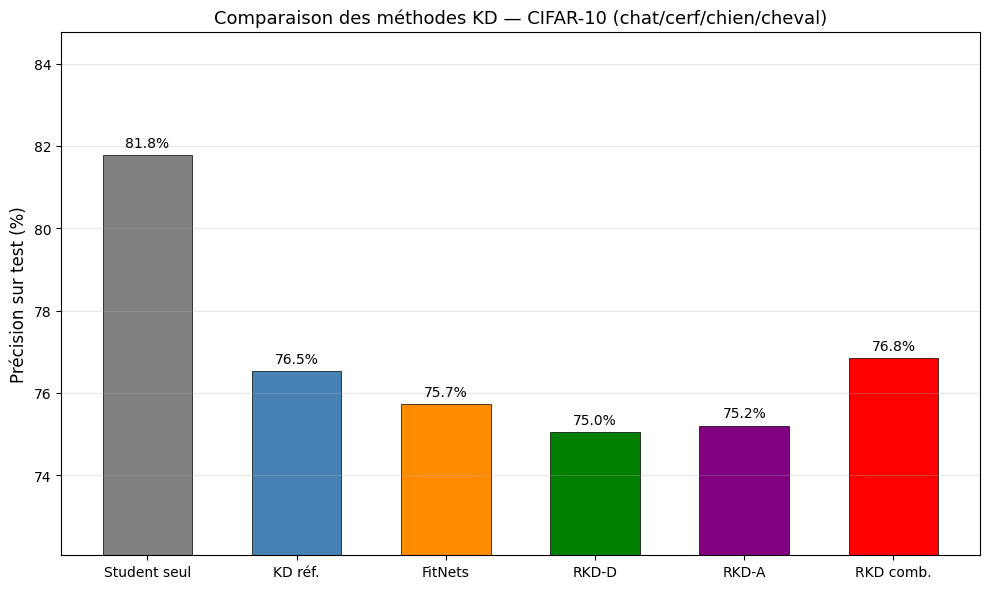

Sauvegardé: final_comparison.png


In [ ]:
print('Knowledge Distillation — Jad Falaq')
print('Toutes les expériences terminées avec succès.')

# Graphique final comparatif
methods_p2 = ['Student seul', 'KD réf.', 'FitNets', 'RKD-D', 'RKD-A', 'RKD comb.']
accs_p2 = [
    hist_cifar_alone['val_acc'][-1] * 100,
    hist_cifar_kd['val_acc'][-1] * 100,
    fitnets_results[best_gamma] * 100,
    rkd_results['RKD-D uniquement'] * 100,
    rkd_results['RKD-A uniquement'] * 100,
    rkd_results['RKD combiné'] * 100,
]

plt.figure(figsize=(10, 6))
colors_bar = ['gray', 'steelblue', 'darkorange', 'green', 'purple', 'red']
bars = plt.bar(methods_p2, accs_p2, color=colors_bar, width=0.6, edgecolor='black', linewidth=0.5)
for bar, acc in zip(bars, accs_p2):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f'{acc:.1f}%', ha='center', fontsize=10)
plt.ylabel('Précision sur test (%)', fontsize=12)
plt.title('Comparaison des méthodes KD — CIFAR-10 (chat/cerf/chien/cheval)', fontsize=13)
plt.ylim(min(accs_p2) - 3, max(accs_p2) + 3)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé: final_comparison.png')